# Teste com modelo SVM

## Import e Separação dos Dados

In [1]:
caminho = '../'

In [2]:
import pandas as pd
#Importar conjuntos de dados

df_dengue = pd.read_csv(caminho + 'database/Dengue.csv')
df_malaria= pd.read_csv(caminho + 'database/Malaria.csv')
df_shared = pd.read_csv(caminho + 'database/Shared.csv')

print(df_dengue.columns)
print(df_dengue['Result'].value_counts())

print(df_malaria.columns)
print(df_malaria['Result'].value_counts())

print(df_shared.columns)
print(df_shared['Result'].value_counts())

Index(['Hemoglobin(Hb%)', 'Total WBC count(/cumm)', 'Neutrophils',
       'Lymphocytes', 'Total Cir.Eosinophils', 'HTC/PCV(%)', 'MCH(pg)',
       'MCHC(g/dl)', 'RDW-CV(%)', 'Platelet Count', 'Result', 'tipo'],
      dtype='object')
Result
0    928
1    671
Name: count, dtype: int64
Index(['Hemoglobin(Hb%)', 'Total WBC count(/cumm)', 'Neutrophils',
       'Lymphocytes', 'Total Cir.Eosinophils', 'HTC/PCV(%)', 'MCH(pg)',
       'MCHC(g/dl)', 'RDW-CV(%)', 'Platelet Count', 'Result', 'tipo'],
      dtype='object')
Result
0    878
1    826
Name: count, dtype: int64
Index(['Hemoglobin(Hb%)', 'Total WBC count(/cumm)', 'Neutrophils',
       'Lymphocytes', 'Total Cir.Eosinophils', 'HTC/PCV(%)', 'MCH(pg)',
       'MCHC(g/dl)', 'RDW-CV(%)', 'Platelet Count', 'Result'],
      dtype='object')
Result
1    242
0    242
Name: count, dtype: int64


In [3]:
# Algumas coisinhas
tipo = df_dengue['tipo'].copy()

X = df_dengue.drop(columns=['Result', 'tipo'], axis=1).copy()
y = df_dengue['Result'].copy()

In [4]:
# Features e Labels
X_train = X[tipo == 'treino']
X_test  = X[tipo == 'teste']
X_val   = df_malaria.drop(columns=['Result', 'tipo'], axis=1).copy()
X_shared= df_shared.drop(columns=['Result'], axis=1).copy()

y_train = y[tipo == 'treino']
y_test  = y[tipo == 'teste']
y_val   = df_malaria['Result'].copy()
y_shared= df_shared['Result'].copy()

print(X_train.shape, X_test.shape, X_val.shape)
print(y_train.shape, y_test.shape, y_val.shape)

(959, 10) (640, 10) (1704, 10)
(959,) (640,) (1704,)


In [5]:
# Normalizar e Padronizar conjunto de dados
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scaler_mim_max = MinMaxScaler()
scaler_mim_max.set_output(transform="pandas")

# Com MinMax Scaler
X_train = scaler_mim_max.fit_transform(X_train)
X_test  = scaler_mim_max.transform(X_test)
X_val   = scaler_mim_max.transform(X_val)
X_shared= scaler_mim_max.transform(X_shared)

## Testar no SVM Default

=== MÉTRICAS DE DESEMPENHO ===

Acurácia: 0.8438
Precisão: 0.8483
Recall:   0.8565
F1-Score: 0.8433
MCC:      0.7047
AUC:      0.8804
--------------------------------------------------


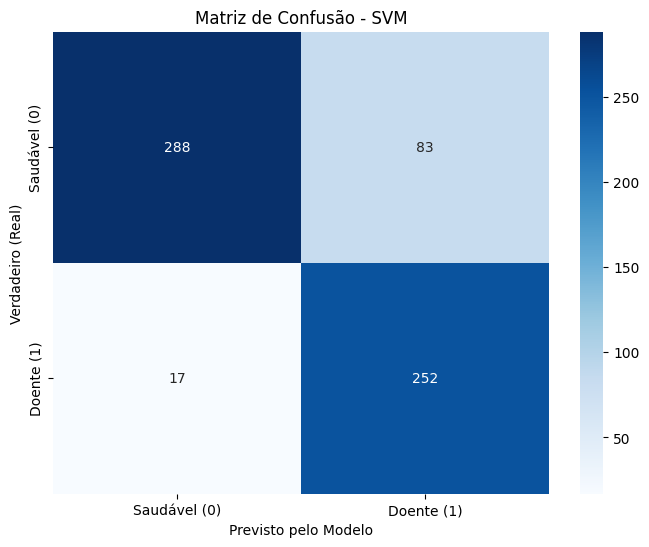

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             matthews_corrcoef, confusion_matrix)

# Modelo
svm = SVC(kernel='rbf', probability=True, random_state=14)
svm.fit(X_train, y_train)

# Fazendo as Previsões
y_pred_def = svm.predict(X_test)
y_prob_def = svm.predict_proba(X_test)[:, 1]

# Métricas
acuracia_def = accuracy_score(y_test, y_pred_def)
precisao_def = precision_score(y_test, y_pred_def, average='macro')
recall_def   = recall_score(y_test, y_pred_def, average='macro')
f1_def       = f1_score(y_test, y_pred_def, average='macro')
mcc_def      = matthews_corrcoef(y_test, y_pred_def)

# O AUC binário recebe as classes reais e as probabilidades diretamente
auc = roc_auc_score(y_test, y_prob_def)

# Exibindo os Resultados
print("=== MÉTRICAS DE DESEMPENHO ===\n")
print(f"Acurácia: {acuracia_def:.4f}")
print(f"Precisão: {precisao_def:.4f}")
print(f"Recall:   {recall_def:.4f}")
print(f"F1-Score: {f1_def:.4f}")
print(f"MCC:      {mcc_def:.4f}")
print(f"AUC:      {auc:.4f}")
print("-" * 50)


# 5. Plotando a Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_def)

# Labels ajustados exclusivamente para as duas doenças
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])

plt.title('Matriz de Confusão - SVM')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

## Otimização de Hiperparâmetros

In [7]:
import optuna
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

def objective(trial):
    # Seleciona o kernel primeiro para poder condicionar outros parâmetros
    kernel = trial.suggest_categorical('kernel', ['rbf', 'poly', 'sigmoid'])

    params = {
        'C': trial.suggest_float('C', 0.1, 100.0, log=True),
        'gamma': trial.suggest_categorical('gamma', ['scale', 'auto']),
        'kernel': kernel,
        'tol': trial.suggest_float('tol', 1e-5, 1e-1, log=True),
        'shrinking': trial.suggest_categorical('shrinking', [True, False]),
        'random_state': 14
    }

    # Hiperparâmetros condicionais
    if kernel == 'poly':
        params['degree'] = trial.suggest_int('degree', 2, 4)
        params['coef0'] = trial.suggest_float('coef0', 0.0, 1.0)
    elif kernel == 'sigmoid':
        params['coef0'] = trial.suggest_float('coef0', 0.0, 1.0)

    clf = SVC(**params, probability=True)

    # Cross-validation
    score = cross_val_score(clf, X_train, y_train.values.ravel(), scoring='f1_macro', cv=5, n_jobs=-1).mean()
    return score

# Criando e executando
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f"Melhor pontuação: {study.best_value:.4f}")
print("Melhores parâmetros:")
print(study.best_params)

# Treinando o modelo final com os melhores parâmetros encontrados
best_svm = SVC(**study.best_params, probability=True, random_state=14)
best_svm.fit(X_train, y_train.values.ravel())

c:\Users\renan\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-07-27 12:38:28,402] A new study created in memory with name: no-name-596b0b11-f2a1-462b-8ef4-0cabe0393090
Best trial: 0. Best value: 0.86391:   2%|▏         | 1/50 [00:04<03:47,  4.65s/it]

[I 2026-07-27 12:38:33,049] Trial 0 finished with value: 0.8639096028979424 and parameters: {'kernel': 'rbf', 'C': 1.3781297509760546, 'gamma': 'scale', 'tol': 0.026548078756133384, 'shrinking': False}. Best is trial 0 with value: 0.8639096028979424.


Best trial: 0. Best value: 0.86391:   4%|▍         | 2/50 [00:07<03:00,  3.76s/it]

[I 2026-07-27 12:38:36,197] Trial 1 finished with value: 0.8240386289392829 and parameters: {'kernel': 'sigmoid', 'C': 2.15129764903535, 'gamma': 'auto', 'tol': 0.0001486830501278475, 'shrinking': True, 'coef0': 0.10732144603356919}. Best is trial 0 with value: 0.8639096028979424.


Best trial: 0. Best value: 0.86391:   8%|▊         | 4/50 [00:09<01:24,  1.83s/it]

[I 2026-07-27 12:38:38,088] Trial 2 finished with value: 0.36741300829281254 and parameters: {'kernel': 'sigmoid', 'C': 0.1098545389560616, 'gamma': 'scale', 'tol': 9.406336867214141e-05, 'shrinking': True, 'coef0': 0.3142801814426166}. Best is trial 0 with value: 0.8639096028979424.
[I 2026-07-27 12:38:38,260] Trial 3 finished with value: 0.36741300829281254 and parameters: {'kernel': 'sigmoid', 'C': 0.5509629705053277, 'gamma': 'scale', 'tol': 0.07093697337672272, 'shrinking': False, 'coef0': 0.9564828177246897}. Best is trial 0 with value: 0.8639096028979424.


... (45 outputs left out)

[I 2026-07-27 12:38:48,833] Trial 46 finished with value: 0.864940060020739 and parameters: {'kernel': 'rbf', 'C': 1.3921668467265154, 'gamma': 'scale', 'tol': 0.0002640473987575647, 'shrinking': False}. Best is trial 22 with value: 0.8649645604117158.
[I 2026-07-27 12:38:48,949] Trial 47 finished with value: 0.8346760213722038 and parameters: {'kernel': 'rbf', 'C': 1.3412418931309564, 'gamma': 'auto', 'tol': 0.0003149522167660925, 'shrinking': False}. Best is trial 22 with value: 0.8649645604117158.


Best trial: 22. Best value: 0.864965: 100%|██████████| 50/50 [00:20<00:00,  2.40it/s]


[I 2026-07-27 12:38:49,050] Trial 48 finished with value: 0.861802801603335 and parameters: {'kernel': 'rbf', 'C': 0.681740173265161, 'gamma': 'scale', 'tol': 0.0009744597518082101, 'shrinking': True}. Best is trial 22 with value: 0.8649645604117158.
[I 2026-07-27 12:38:49,206] Trial 49 finished with value: 0.49404601935691195 and parameters: {'kernel': 'sigmoid', 'C': 3.616698562496811, 'gamma': 'scale', 'tol': 0.00018816047152619438, 'shrinking': False, 'coef0': 0.36702980218367554}. Best is trial 22 with value: 0.8649645604117158.
Melhor pontuação: 0.8650
Melhores parâmetros:
{'kernel': 'rbf', 'C': 1.5577174548058639, 'gamma': 'scale', 'tol': 0.00042704667869966086, 'shrinking': False}


,C,1.5577174548058639
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,False
,probability,True
,tol,0.00042704667869966086
,cache_size,200
,class_weight,None
,verbose,False


In [8]:
fig = optuna.visualization.plot_param_importances(study)
fig.show()

fig = optuna.visualization.plot_optimization_history(study)
fig.show()

=== MÉTRICAS DE DESEMPENHO ===

Acurácia: 0.8422
Precisão: 0.8444
Recall:   0.8531
F1-Score: 0.8415
MCC:      0.6975
AUC:      0.8805
--------------------------------------------------


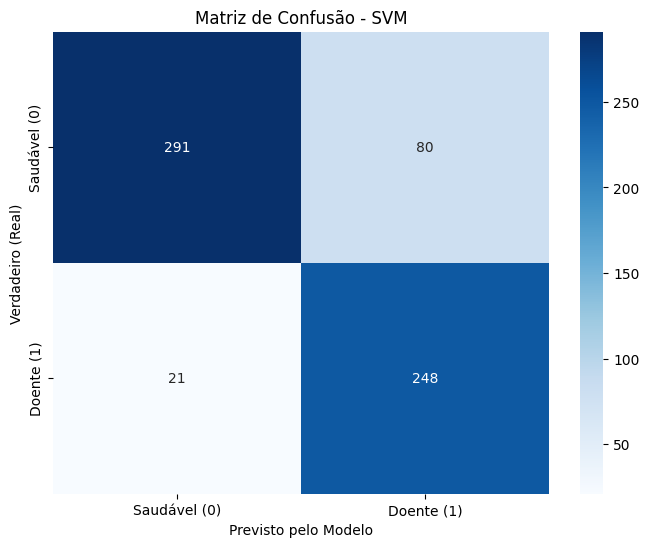

In [9]:
# Fazendo as Previsões
y_pred_best = best_svm.predict(X_test)
y_prob_best = best_svm.predict_proba(X_test)[:, 1]

# Métricas
acuracia_best = accuracy_score(y_test, y_pred_best)
precisao_best = precision_score(y_test, y_pred_best, average='macro')
recall_best   = recall_score(y_test, y_pred_best, average='macro')
f1_best       = f1_score(y_test, y_pred_best, average='macro')
mcc_best      = matthews_corrcoef(y_test, y_pred_best)

# O AUC binário recebe as classes reais e as probabilidades diretamente
auc = roc_auc_score(y_test, y_prob_best)

# Exibindo os Resultados
print("=== MÉTRICAS DE DESEMPENHO ===\n")
print(f"Acurácia: {acuracia_best:.4f}")
print(f"Precisão: {precisao_best:.4f}")
print(f"Recall:   {recall_best:.4f}")
print(f"F1-Score: {f1_best:.4f}")
print(f"MCC:      {mcc_best:.4f}")
print(f"AUC:      {auc:.4f}")
print("-" * 50)


# 5. Plotando a Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_best)

# Labels ajustados exclusivamente para as duas doenças
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])

plt.title('Matriz de Confusão - SVM')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

# Validação Externa

=== MÉTRICAS DE DESEMPENHO ===

Acurácia: 0.6338
Precisão: 0.6384
Recall:   0.6360
F1-Score: 0.6328
MCC:      0.2744
AUC:      0.6761
--------------------------------------------------


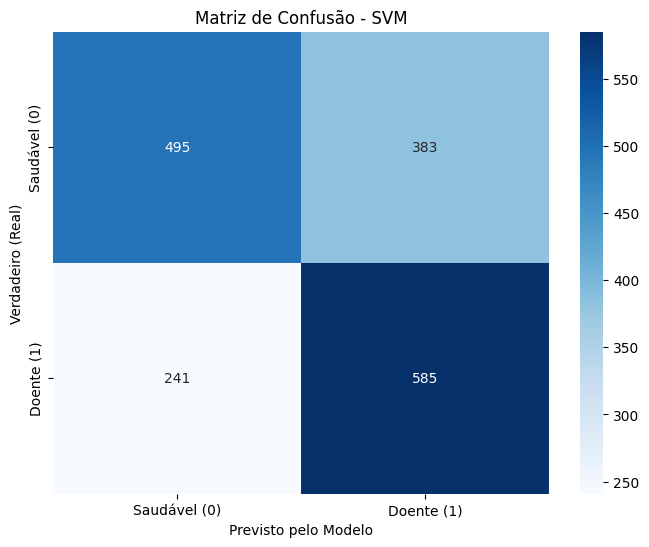

In [10]:
# Fazendo as Previsões
y_pred_val = best_svm.predict(X_val)
y_prob_val = best_svm.predict_proba(X_val)[:, 1]

# Métricas
acuracia_val = accuracy_score(y_val, y_pred_val)
precisao_val = precision_score(y_val, y_pred_val, average='macro')
recall_val   = recall_score(y_val, y_pred_val, average='macro')
f1_val       = f1_score(y_val, y_pred_val, average='macro')
mcc_val      = matthews_corrcoef(y_val, y_pred_val)

# O AUC binário recebe as classes reais e as probabilidades diretamente
auc = roc_auc_score(y_val, y_prob_val)

# Exibindo os Resultados
print("=== MÉTRICAS DE DESEMPENHO ===\n")
print(f"Acurácia: {acuracia_val:.4f}")
print(f"Precisão: {precisao_val:.4f}")
print(f"Recall:   {recall_val:.4f}")
print(f"F1-Score: {f1_val:.4f}")
print(f"MCC:      {mcc_val:.4f}")
print(f"AUC:      {auc:.4f}")
print("-" * 50)


# 5. Plotando a Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_val, y_pred_val)

# Labels ajustados exclusivamente para as duas doenças
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])

plt.title('Matriz de Confusão - SVM')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

=== VALIDAÇÃO EXTERNA SHARED ===

Acurácia: 0.5496
Precisão: 0.5780
Recall: 0.5496
F1-Score: 0.5045
MCC: 0.1244
AUC: 0.5817
--------------------------------------------------


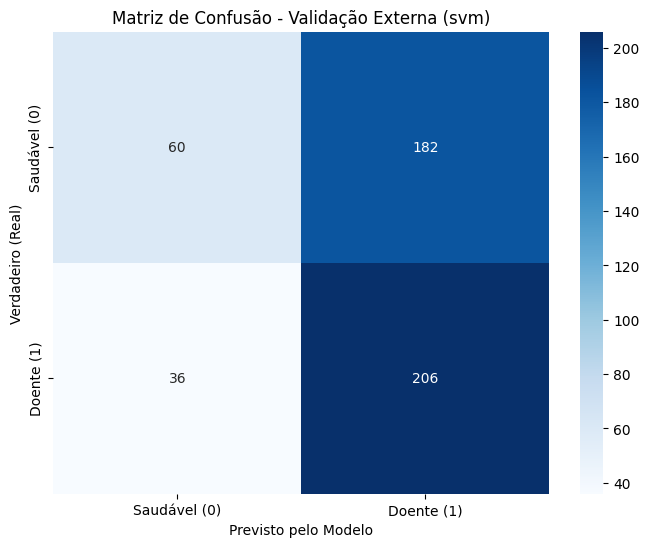

In [11]:
import numpy as np

y_true_shared = np.array(y_shared).ravel()
y_pred_shared = best_svm.predict(X_shared)
y_prob_shared = best_svm.predict_proba(X_shared)[:, 1]

# Métricas na Validação Externa
acuracia_shared = accuracy_score(y_true_shared, y_pred_shared)
precisao_shared = precision_score(y_true_shared, y_pred_shared, average='macro', zero_division=0)
recall_shared = recall_score(y_true_shared, y_pred_shared, average='macro', zero_division=0)
f1_shared = f1_score(y_true_shared, y_pred_shared, average='macro', zero_division=0)
mcc_shared = matthews_corrcoef(y_true_shared, y_pred_shared)
auc_shared = roc_auc_score(y_true_shared, y_prob_shared)

print("=== VALIDAÇÃO EXTERNA SHARED ===\n")
print(f"Acurácia: {acuracia_shared:.4f}")
print(f"Precisão: {precisao_shared:.4f}")
print(f"Recall: {recall_shared:.4f}")
print(f"F1-Score: {f1_shared:.4f}")
print(f"MCC: {mcc_shared:.4f}")
print(f"AUC: {auc_shared:.4f}")
print("-" * 50)

# Matriz de Confusão Externa
plt.figure(figsize=(8, 6))
cm_shared = confusion_matrix(y_true_shared, y_pred_shared)
sns.heatmap(cm_shared, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])
plt.title('Matriz de Confusão - Validação Externa (svm)')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

In [ ]:
import pandas as pd

# Mude apenas o nome do modelo aqui
nome_modelo = 'svm'

arquivo_pred = caminho + 'treino_dengue/saidas/predicoes.csv'
arquivo_proba = caminho + 'treino_dengue/saidas/probabilidades.csv'


# Cria uma lista começando com o nome, o conjunto e depois todas as predições
linha_pred_teste = [nome_modelo, 'teste'] + list(y_pred_best)
linha_pred_val = [nome_modelo, 'validacao'] + list(y_pred_val)
linha_pred_shared = [nome_modelo, 'shared'] + list(y_pred_shared)


# Salva adicionando as linhas embaixo (mode='a') sem cabeçalho
pd.DataFrame([linha_pred_teste, linha_pred_val, linha_pred_shared]).to_csv(arquivo_pred, mode='a', header=False, index=False)


# Probas
linha_proba_teste = [nome_modelo, 'teste'] + list(y_prob_best)
linha_proba_val = [nome_modelo, 'validacao'] + list(y_prob_val)
linha_proba_shared = [nome_modelo, 'shared'] + list(y_prob_shared)

pd.DataFrame([linha_proba_teste, linha_proba_val, linha_proba_shared]).to_csv(arquivo_proba, mode='a', header=False, index=False)

print(f"Linhas do modelo {nome_modelo} adicionadas com sucesso!")

Linhas do modelo knn adicionadas com sucesso!
